In [1]:
# =============================================================================
# PASO 1: IMPORTACIÓN DE LIBRERÍAS Y CARGA DE DATOS
# =============================================================================

# Importamos las librerías esenciales para manipulación de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo visual básico para los gráficos
sns.set_theme(style="whitegrid")

# URL oficial del dataset de vino tinto (del repositorio UCI Machine Learning)
url_datos = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

# Cargamos el archivo CSV.
# Nota importante: este dataset utiliza punto y coma (;) como separador en lugar de coma.
df = pd.read_csv(url_datos, sep=";")

# Mostramos un mensaje de confirmación
print("Dataset cargado exitosamente.")
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

# Mostramos las primeras 5 filas para verificar que las columnas se leyeron bien
print("Primeras 5 filas del dataset:")
df.head()

Dataset cargado exitosamente.
Dimensiones del dataset: 1599 filas y 12 columnas.

Primeras 5 filas del dataset:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### **Descripción del Dataset: Calidad del Vino Tinto (*Wine Quality*)**

* **Registros:** 1,599 muestras de vino tinto (*Vinho Verde* del norte de Portugal).  
* **Variables predictoras (11 fisicoquímicas continuas):**  
  * fixed acidity: Acidez fija (ácidos que no se evaporan con facilidad, ej. ácido tartárico).  
  * volatile acidity: Acidez volátil (ácidos que se evaporan; niveles altos dan sabor a vinagre).  
  * citric acid: Ácido cítrico (aporta frescura y sabor).  
  * residual sugar: Azúcar residual (cantidad remanente tras la fermentación).  
  * chlorides: Cloruros (cantidad de sal en el vino).  
  * free sulfur dioxide: Dióxido de azufre libre (previene el crecimiento microbiano y la oxidación).  
  * total sulfur dioxide: Dióxido de azufre total (suma de formas libres y ligadas).  
  * density: Densidad del vino (asociada al porcentaje de alcohol y azúcar).  
  * pH: Nivel de pH (escala de 0 a 14 que mide qué tan ácido o básico es el vino).  
  * sulphates: Sulfatos (aditivo que contribuye a los niveles de dióxido de azufre).  
  * alcohol: Porcentaje de alcohol por volumen.  
* **Variable objetivo (*Target*):**  
  * quality: Calificación numérica sensorial otorgada por expertos en una escala del 0 al 10 (variable numérica entera que usaremos como objetivo).

--- RESUMEN DE TIPOS DE DATOS Y VALORES NO NULOS ---
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

--- ESTADÍSTICAS DESCRIPTIVAS BÁSICAS ---
       fixed acidity  volatile acidity  c

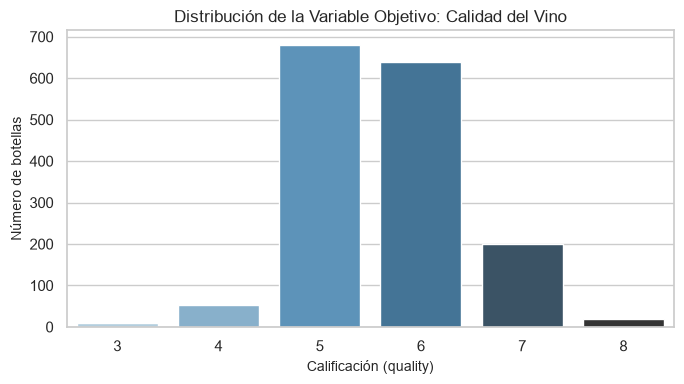

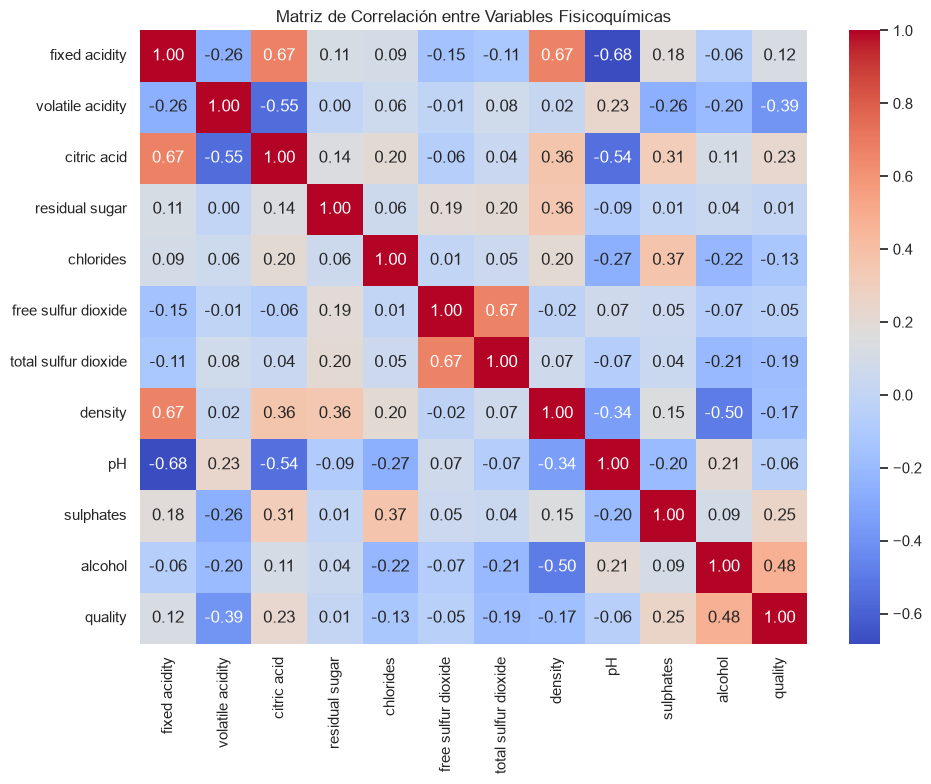

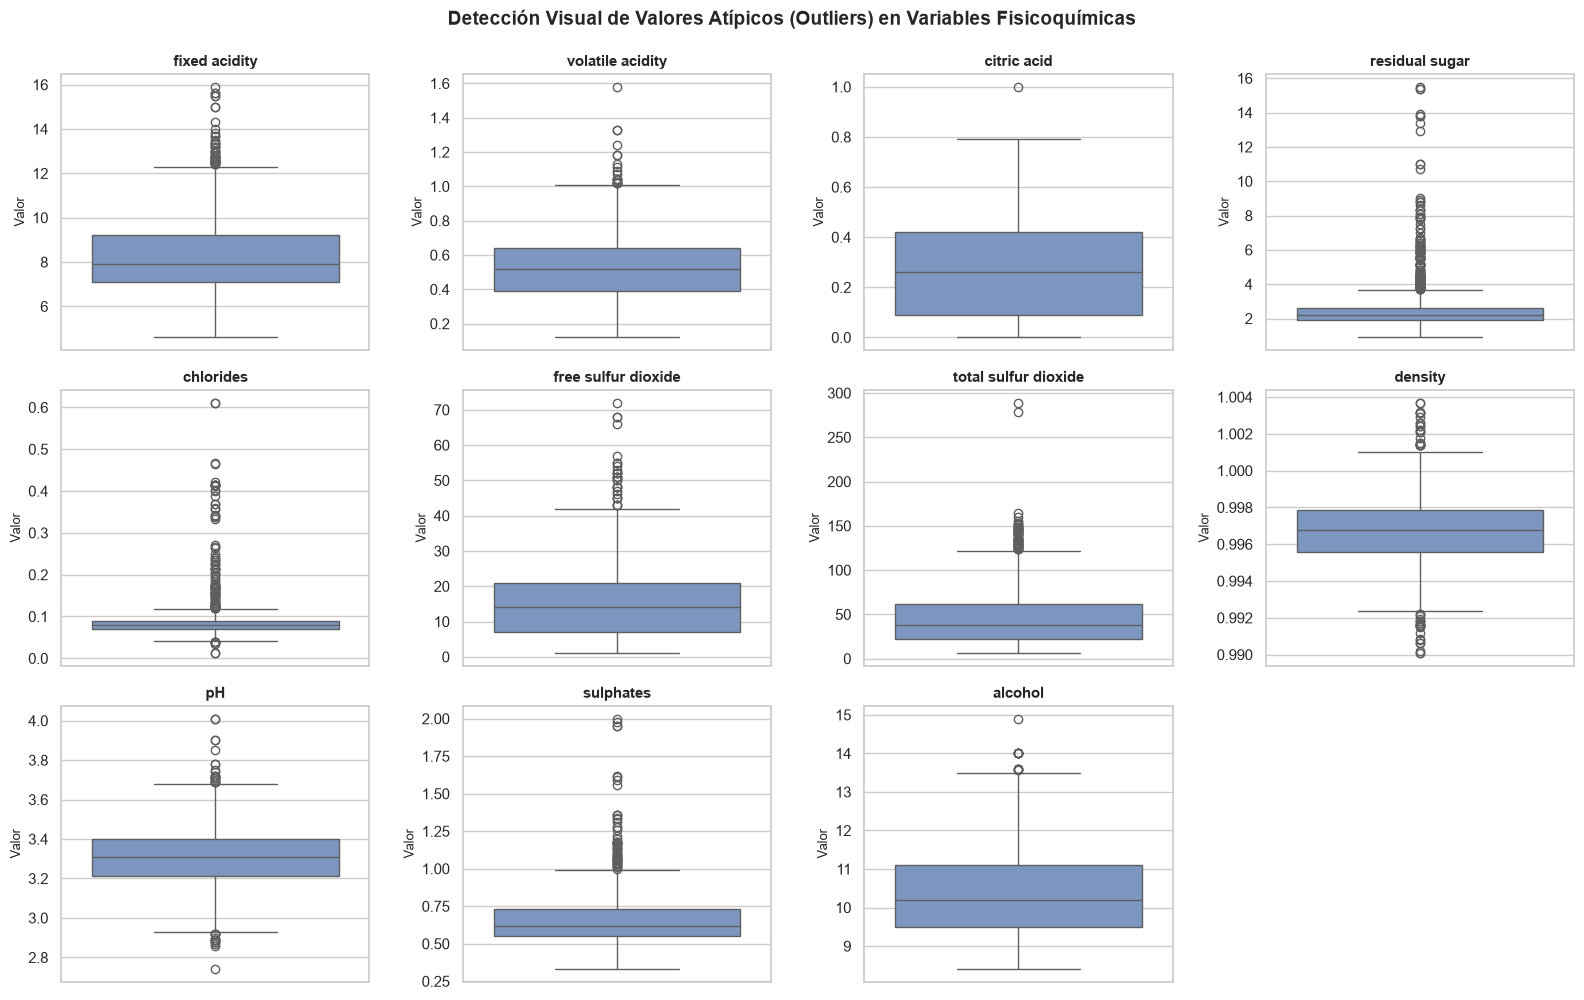

In [2]:
# =============================================================================
# PASO 2: ANÁLISIS EXPLORATORIO DE DATOS (EDA)
# =============================================================================

# 1. Inspección de tipos de datos y valores no nulos
print("--- RESUMEN DE TIPOS DE DATOS Y VALORES NO NULOS ---")
df.info()

print("\n--- ESTADÍSTICAS DESCRIPTIVAS BÁSICAS ---")
# Redondeamos a 2 decimales para facilitar la lectura
print(df.describe().round(2))

# 2. Visualización de la variable objetivo (quality)
# Es vital ver si las calificaciones están equilibradas o concentradas al centro
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="quality", palette="Blues_d", hue="quality", legend=False)
plt.title("Distribución de la Variable Objetivo: Calidad del Vino", fontsize=12)
plt.xlabel("Calificación (quality)", fontsize=10)
plt.ylabel("Número de botellas", fontsize=10)
plt.tight_layout()
plt.show()

# 3. Matriz de correlación
# Ayuda a identificar qué variables químicas se relacionan más con la calidad
plt.figure(figsize=(10, 8))
matriz_correlacion = df.corr()

# Dibujamos el mapa de calor mostrando el número de correlación en cada cuadro
sns.heatmap(matriz_correlacion, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Matriz de Correlación entre Variables Fisicoquímicas", fontsize=12)
plt.tight_layout()
plt.show()

# =============================================================================
# VISUALIZACIÓN DE OUTLIERS CON DIAGRAMAS DE CAJA (BOXPLOTS)
# =============================================================================

# Obtenemos la lista de las 11 características fisicoquímicas (excluyendo quality)
columnas_fisicoquimicas = df.drop(columns=["quality"]).columns

# Configuramos una figura con una cuadrícula de 3 filas por 4 columnas
# Esto nos da 12 espacios para graficar cada variable de forma individual
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10))

# Aplanamos la cuadrícula de ejes a una lista simple para recorrerla en orden
axes = axes.flatten()

# Dibujamos un diagrama de caja para cada una de las 11 variables
for indice, columna in enumerate(columnas_fisicoquimicas):
    # sns.boxplot muestra la caja (IQR) y los puntos aislados (outliers)
    sns.boxplot(y=df[columna], ax=axes[indice], color="#7293CB")
    axes[indice].set_title(columna, fontsize=11, fontweight="bold")
    axes[indice].set_ylabel("Valor", fontsize=9)
    axes[indice].set_xlabel("")

# Como tenemos 11 variables y la cuadrícula tiene 12 lugares, apagamos el último espacio vacío
axes[11].set_visible(False)

# Título general de la figura y ajuste de márgenes
plt.suptitle(
    "Detección Visual de Valores Atípicos (Outliers) en Variables Fisicoquímicas",
    fontsize=14,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout()
plt.show()

### Hallazgos del Análisis Exploratorio de Datos (EDA)

1. **Comportamiento del objetivo (`quality`):** La variable toma valores enteros del 3 al 8, con una media de 5.64. Las categorías 5 y 6 concentran más del 80% de los datos, mostrando una distribución unimodal con baja presencia de vinos excelentes (7 u 8) o defectuosos (3 o 4).
2. **Relaciones principales:** El porcentaje de alcohol presenta la correlación positiva más relevante con la calidad (+0.48), mientras que la acidez volátil tiene una correlación negativa destacada (-0.39).
3. **Multicolinealidad:** Se observan correlaciones esperadas por la naturaleza química del vino, tales como la relación inversa entre acidez fija y pH (-0.68).

#### Análisis Detallado de Valores Atípicos mediante Boxplots

La inspección de los 11 diagramas de caja revela tres patrones principales en la química de las muestras:

1. **Variables con fuerte asimetría positiva (sesgo a la derecha):**
   * `residual sugar` y `chlorides` presentan un rango intercuartílico sumamente estrecho en valores bajos, pero exhiben una densa estela de valores atípicos hacia arriba. Esto indica que la gran mayoría de los vinos son secos y bajos en sal, existiendo lotes minoritarios más dulces o salinos.
   * `total sulfur dioxide` y `free sulfur dioxide` presentan colas largas hacia valores elevados, destacando dos botellas que rozan los 300 mg/dm³ de sulfuro total.

2. **Variables con dispersión simétrica y valores atípicos bilaterales:**
   * `pH` y `density` muestran cajas centradas donde los valores atípicos ocurren simétricamente en ambos extremos (superior e inferior), confirmando un comportamiento estadístico de tipo normal o gaussiano.

3. **Implicaciones para el modelado y MLOps:**
   * La marcada disparidad en las magnitudes numéricas (desde milésimas en `density` hasta cientos de unidades en `total sulfur dioxide`) y la presencia de colas largas justifican la necesidad de estandarizar las variables predictoras mediante una tubería de preprocesamiento (`StandardScaler`) acoplada al estimador, garantizando que los algoritmos de optimización converjan de forma eficiente, estable y sin advertencias numéricas.

In [3]:
# =============================================================================
# PASO 3: DIAGNÓSTICO DE LIMPIEZA DE DATOS
# =============================================================================

# 1. Verificamos si existen valores nulos en alguna columna
print("--- 1. CONTEO DE VALORES NULOS POR COLUMNA ---")
valores_nulos = df.isnull().sum()
print(valores_nulos)

# 2. Verificamos si existen filas duplicadas en el dataset
filas_duplicadas = df.duplicated().sum()
print(f"\n--- 2. FILAS DUPLICADAS ---")
print(f"Total de filas duplicadas encontradas: {filas_duplicadas}")

# 3. Inspeccionamos datos atípicos (outliers) usando el Rango Intercuartílico (IQR)
# Revisamos cuántos registros caen fuera de los límites comunes en variables clave
print("\n--- 3. DETECCIÓN DE POSIBLES OUTLIERS (MÉTODO IQR) ---")
columnas_clave = ["residual sugar", "chlorides", "total sulfur dioxide"]

for columna in columnas_clave:
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    
    conteo_outliers = ((df[columna] < limite_inferior) | (df[columna] > limite_superior)).sum()
    print(f"Variable '{columna}': {conteo_outliers} registros fuera de rango normal.")

--- 1. CONTEO DE VALORES NULOS POR COLUMNA ---
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

--- 2. FILAS DUPLICADAS ---
Total de filas duplicadas encontradas: 240

--- 3. DETECCIÓN DE POSIBLES OUTLIERS (MÉTODO IQR) ---
Variable 'residual sugar': 155 registros fuera de rango normal.
Variable 'chlorides': 112 registros fuera de rango normal.
Variable 'total sulfur dioxide': 55 registros fuera de rango normal.


Dimensiones originales: (1599, 12)
Dimensiones después de eliminar duplicados: (1359, 12)
Filas eliminadas exitosamente: 240



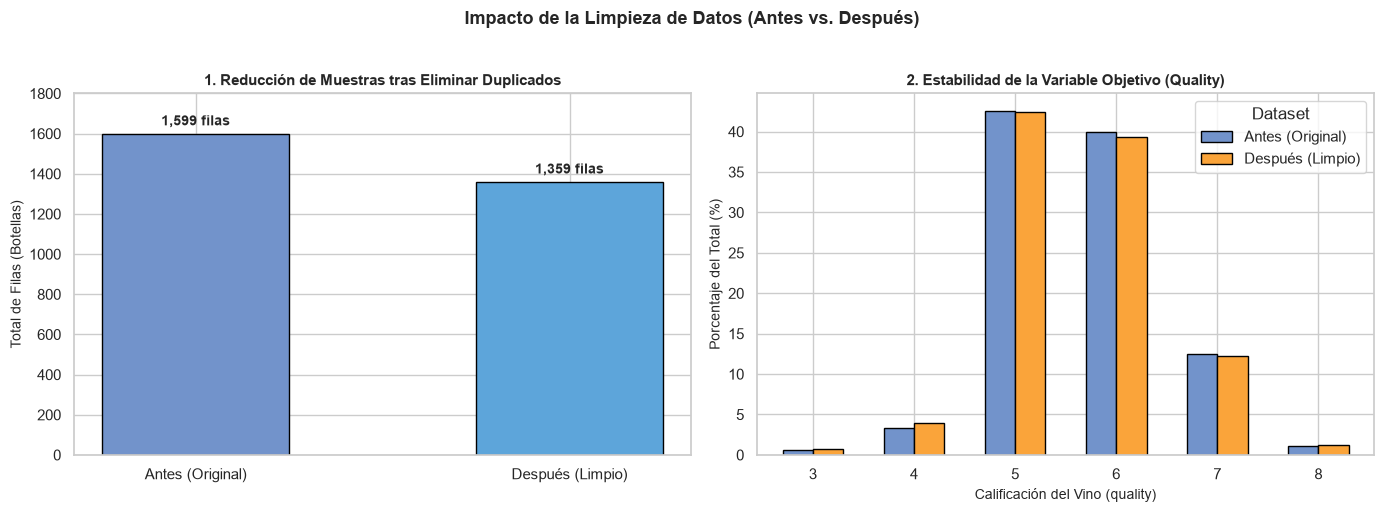

In [4]:
# =============================================================================
# PASO 3 : LIMPIEZA
# =============================================================================

# 1. Eliminamos los duplicados y guardamos un nuevo dataframe limpio
df_limpio = df.drop_duplicates().copy()

print(f"Dimensiones originales: {df.shape}")
print(f"Dimensiones después de eliminar duplicados: {df_limpio.shape}")
print(f"Filas eliminadas exitosamente: {df.shape[0] - df_limpio.shape[0]}\n")

# =============================================================================
# VISUALIZACIÓN DEL ANTES Y DESPUÉS DE LA LIMPIEZA
# =============================================================================

# 1. Creamos una figura con 2 subgráficas en una sola fila (1 fila, 2 columnas)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# -----------------------------------------------------------------------------
# GRÁFICA 1: Comparación del número total de registros
# -----------------------------------------------------------------------------
etiquetas_filas = ["Antes (Original)", "Después (Limpio)"]
conteos_filas = [len(df), len(df_limpio)]
colores_barras = ["#7293CB", "#5DA5DA"]

barras = axes[0].bar(
    etiquetas_filas,
    conteos_filas,
    color=colores_barras,
    edgecolor="black",
    width=0.5,
)

# Agregamos el número exacto encima de cada barra para mayor claridad
for barra in barras:
    altura = barra.get_height()
    axes[0].annotate(
        f"{altura:,} filas",
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

axes[0].set_title(
    "1. Reducción de Muestras tras Eliminar Duplicados",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_ylabel("Total de Filas (Botellas)", fontsize=10)
axes[0].set_ylim(0, 1800)

# -----------------------------------------------------------------------------
# GRÁFICA 2: Comparación de la distribución porcentual de la variable 'quality'
# -----------------------------------------------------------------------------
# Calculamos el porcentaje que representa cada calificación en ambos datasets
pct_antes = (df["quality"].value_counts(normalize=True).sort_index() * 100)
pct_despues = (
    df_limpio["quality"].value_counts(normalize=True).sort_index() * 100
)

# Unimos ambos cálculos en una pequeña tabla para graficar lado a lado
df_comparativa_calidad = pd.DataFrame(
    {"Antes (Original)": pct_antes, "Después (Limpio)": pct_despues}
)

# Graficamos barras agrupadas por calificación
df_comparativa_calidad.plot(
    kind="bar",
    ax=axes[1],
    color=["#7293CB", "#FAA43A"],
    edgecolor="black",
    width=0.6,
)

axes[1].set_title(
    "2. Estabilidad de la Variable Objetivo (Quality)",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Calificación del Vino (quality)", fontsize=10)
axes[1].set_ylabel("Porcentaje del Total (%)", fontsize=10)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].legend(title="Dataset")

# Ajustamos márgenes y mostramos las figuras
plt.suptitle(
    "Impacto de la Limpieza de Datos (Antes vs. Después)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

### Paso 3: Documentación y Justificación de las Decisiones de Limpieza

En cumplimiento con los requerimientos de calidad de datos, se analizaron cuatro aspectos clave:

1. **Valores nulos o faltantes:**
   * La base no presenta valores faltantes en ninguna de sus 12 columnas (0 nulos). No se requirieron técnicas de imputación estadística.
2. **Filas duplicadas:**
   * Se identificaron 240 filas idénticas. Se tomó la decisión de eliminarlas para evitar que observaciones repetidas aparezcan simultáneamente en el conjunto de entrenamiento y en el de prueba, previniendo fuga de información (*data leakage*) y sobreestimaciones en la métrica. El tamaño final quedó en 1,359 registros.
3. **Tratamiento de valores atípicos (*Outliers*):**
   * El diagnóstico por Rango Intercuartílico (IQR) detectó registros extremos en variables como azúcar residual, cloruros y dióxido de azufre.
   * **Decisión justificada:** Se conservaron todas estas observaciones. En la industria vitivinícola, estas variaciones no corresponden a errores tipográficos ni a fallas de medición, sino a características genuinas del producto (vinos de cosechas más dulces o lotes con mayor adición de conservadores sulfitados). Removerlos mutilaría la varianza natural del fenómeno analizado.
4. **Tipos de datos:**
   * Las 11 variables predictoras son continuas (`float64`) y la variable objetivo es entera (`int64`), por lo que no fue necesario aplicar codificación categórica (*encoding*).

In [5]:
# =============================================================================
# PASO 4 : PARTICIÓN DE DATOS (PREVENCIÓN DE DATA LEAKAGE)
# =============================================================================

from sklearn.model_selection import train_test_split

# 2. Separamos las variables predictoras (X) de la variable objetivo (y)
# X contiene las 11 propiedades fisicoquímicas
X = df_limpio.drop(columns=["quality"])

# y contiene únicamente la calificación del vino
y = df_limpio["quality"]

# 3. Dividimos los datos en conjunto de entrenamiento (80%) y prueba (20%)
# Usamos random_state=42 para que el resultado sea siempre reproducible
# stratify=y asegura que la proporción de calificaciones sea igual en train y test
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

# Mostramos el tamaño final de cada partición
print("--- TAMAÑO DE LOS CONJUNTOS DE DATOS ---")
print(f"Entrenamiento (X_train): {X_train.shape[0]} muestras (para aprender)")
print(f"Prueba (X_test):         {X_test.shape[0]} muestras (para evaluar)")

--- TAMAÑO DE LOS CONJUNTOS DE DATOS ---
Entrenamiento (X_train): 1087 muestras (para aprender)
Prueba (X_test):         272 muestras (para evaluar)


### Pasos 4 y 5: Selección del Modelo Base (Baseline) y Métrica de Desempeño

1. **Modelo Base Seleccionado:** Se eligió una **Regresión Logística multiclase** (`LogisticRegression`).
   * *Justificación:* Al ser un modelo lineal, simple y de bajo costo computacional, establece el umbral mínimo de comparación. Su objetivo pedagógico no es ser perfecto, sino servir de punto de partida: cualquier algoritmo más sofisticado que se pruebe después deberá superar este resultado para justificar su complejidad.
2. **Métricas de Evaluación Justificadas:**
   * **Exactitud (Accuracy):** Mide el porcentaje global de aciertos del modelo.
   * **F1-Score Ponderado (Weighted F1):** En el análisis exploratorio comprobamos que las calificaciones 5 y 6 concentran la inmensa mayoría de las muestras. La exactitud por sí sola puede ser engañosa si el modelo ignora las clases raras; el F1-Score ponderado calcula el balance entre precisión y exhaustividad tomando en cuenta el tamaño de cada clase.

In [6]:
# =============================================================================
# PASOS 4, 5 Y 6: MODELO BASE (CON ESCALADO), EVALUACIÓN Y MLFLOW TRACKING
# =============================================================================

# 1. Importamos MLflow y las herramientas necesarias de Scikit-Learn
import mlflow
import mlflow.sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 2. Conectamos con el servidor local de MLflow
# Recuerda tener ejecutado 'mlflow ui' en tu terminal
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Definimos el experimento general
nombre_experimento = "Wine_Quality_Baseline"
mlflow.set_experiment(nombre_experimento)

# 3. Definimos los hiperparámetros de la regresión logística
hiperparametros = {
    "solver": "lbfgs",
    "max_iter": 1000,
    "random_state": 42
}

# 4. Construimos un Pipeline que une el escalador y el modelo
# StandardScaler resta la media y divide entre la desviación estándar
# Al estar en un Pipeline, aprende solo de X_train y previene fuga de datos (data leakage)
pipeline_modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", LogisticRegression(**hiperparametros))
])

# 5. Iniciamos la corrida de registro dentro de MLflow
with mlflow.start_run(run_name="baseline_regresion_logistica"):
    
    # Entrenamos el pipeline completo
    # El escalador se ajusta con X_train y luego entrena la regresión logística
    pipeline_modelo.fit(X_train, y_train)
    
    # Generamos las predicciones sobre el conjunto de prueba
    # El pipeline escala X_test automáticamente usando los valores aprendidos de X_train
    y_pred = pipeline_modelo.predict(X_test)
    
    # Calculamos las métricas de desempeño
    exactitud = accuracy_score(y_test, y_pred)
    f1_ponderado = f1_score(y_test, y_pred, average="weighted")
    
    # 6. Registramos los hiperparámetros en MLflow
    mlflow.log_params(hiperparametros)
    mlflow.log_param("preprocesamiento", "StandardScaler")
    
    # Registramos las métricas de desempeño
    mlflow.log_metrics({
        "accuracy": exactitud,
        "f1_score_weighted": f1_ponderado
    })
    
    # Agregamos etiquetas descriptivas sobre la corrida
    mlflow.set_tags({
        "tipo_modelo": "Pipeline_StandardScaler_LogisticRegression",
        "etapa": "Baseline_Oficial"
    })
    
    # 7. Registramos el pipeline completo como artefacto reproducible
    # Usamos name en lugar de artifact_path para evitar advertencias de obsolescencia
    mlflow.sklearn.log_model(
        sk_model=pipeline_modelo,
        name="modelo_baseline"
    )
    
    print("¡Corrida registrada exitosamente en MLflow!")

# 8. Mostramos los resultados finales obtenidos en pantalla
print("\n--- RESULTADOS DEL MODELO BASE (CON ESCALADO) ---")
print(f"Exactitud (Accuracy):      {exactitud:.4f} ({exactitud * 100:.2f}%)")
print(f"F1-Score Ponderado:        {f1_ponderado:.4f} ({f1_ponderado * 100:.2f}%)")

2026/10/09 20:18:25 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


¡Corrida registrada exitosamente en MLflow!
🏃 View run baseline_regresion_logistica at: http://127.0.0.1:5000/#/experiments/2/runs/a60d0567eb014f85ba558593a048e5e2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

--- RESULTADOS DEL MODELO BASE (CON ESCALADO) ---
Exactitud (Accuracy):      0.5809 (58.09%)
F1-Score Ponderado:        0.5541 (55.41%)


### Paso 5 (Interpretación): Análisis del Desempeño del Modelo Base Estandarizado

Tras evaluar el pipeline en el conjunto de prueba independiente (272 observaciones), se obtuvieron las siguientes métricas:
* **Exactitud (Accuracy):** 58.09%
* **F1-Score Ponderado:** 55.41%

**Interpretación de resultados:**
1. **Convergencia matemática y comparativa con el baseline ingenuo:** Al estandarizar las variables mediante `StandardScaler`, el optimizador convergió sin advertencias. El desempeño del 58.09% supera con claridad a un clasificador trivial que solo prediga la clase mayoritaria (~42%), demostrando que el modelo extrae valor predictivo real de los componentes químicos del vino.
2. **Impacto del desbalance de clases:** El F1-Score ponderado (55.41%) refleja la dificultad inherente del algoritmo para predecir las categorías enológicas minoritarias (calidades 3, 4, 7 y 8). La mayor parte de los aciertos se concentran en las calificaciones 5 y 6.
3. **Punto de partida para el ciclo MLOps:** Este pipeline representa la referencia base oficial del proyecto. En las actividades posteriores, cualquier modelo más complejo (como Random Forest o Gradient Boosting) deberá superar este 58.09% de exactitud para justificar su costo de cómputo y mantenimiento en producción.

### Paso 6: Evidencia Visual: Capturas de Pantalla de MLFlow

Evidencia 1: Panel general de corridas en MLflow UI


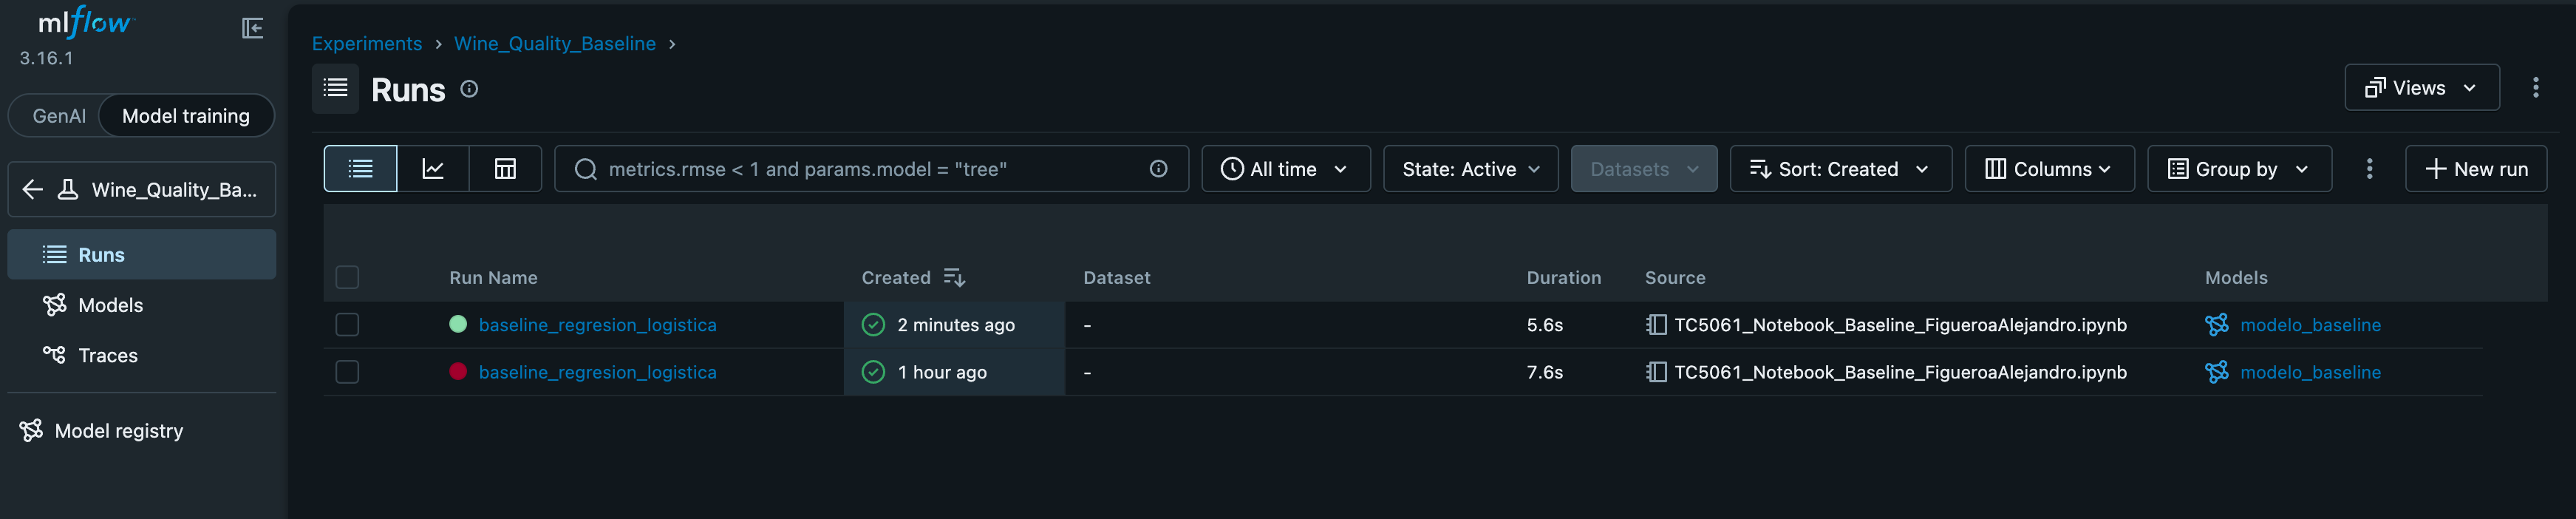


Evidencia 2: Registro de parámetros, métricas


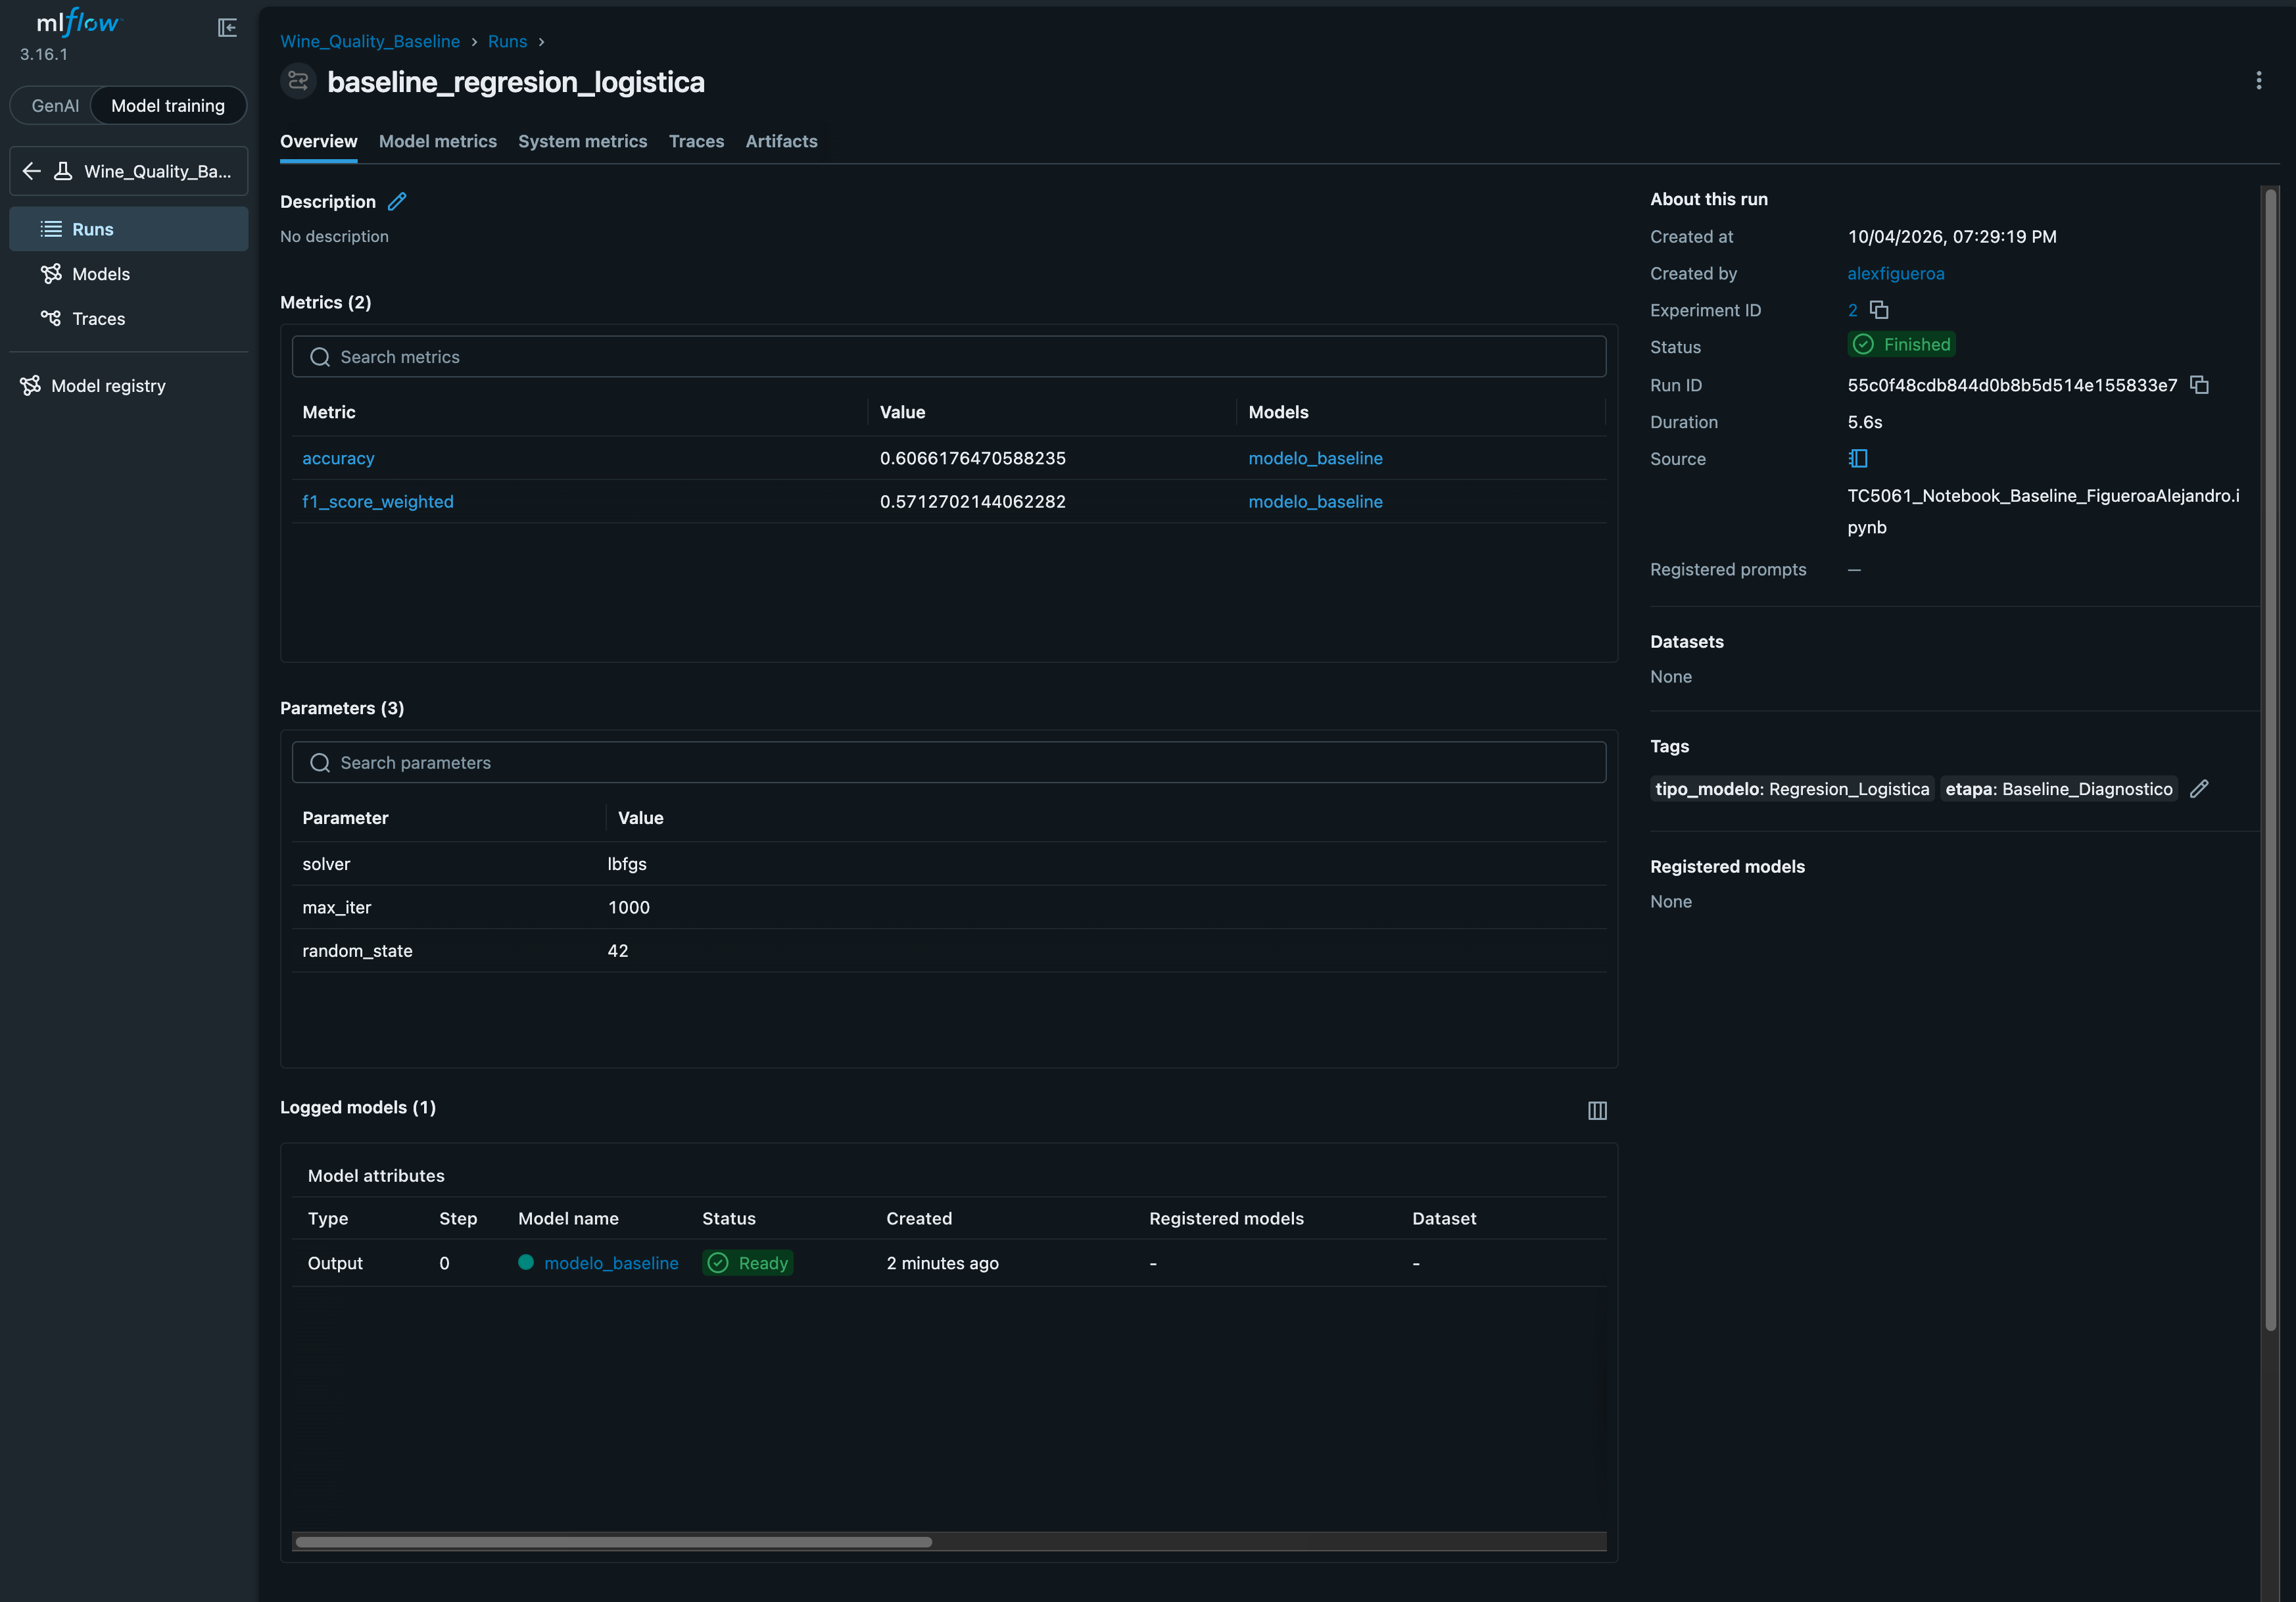


Evidencia 3: Artefactos guardados


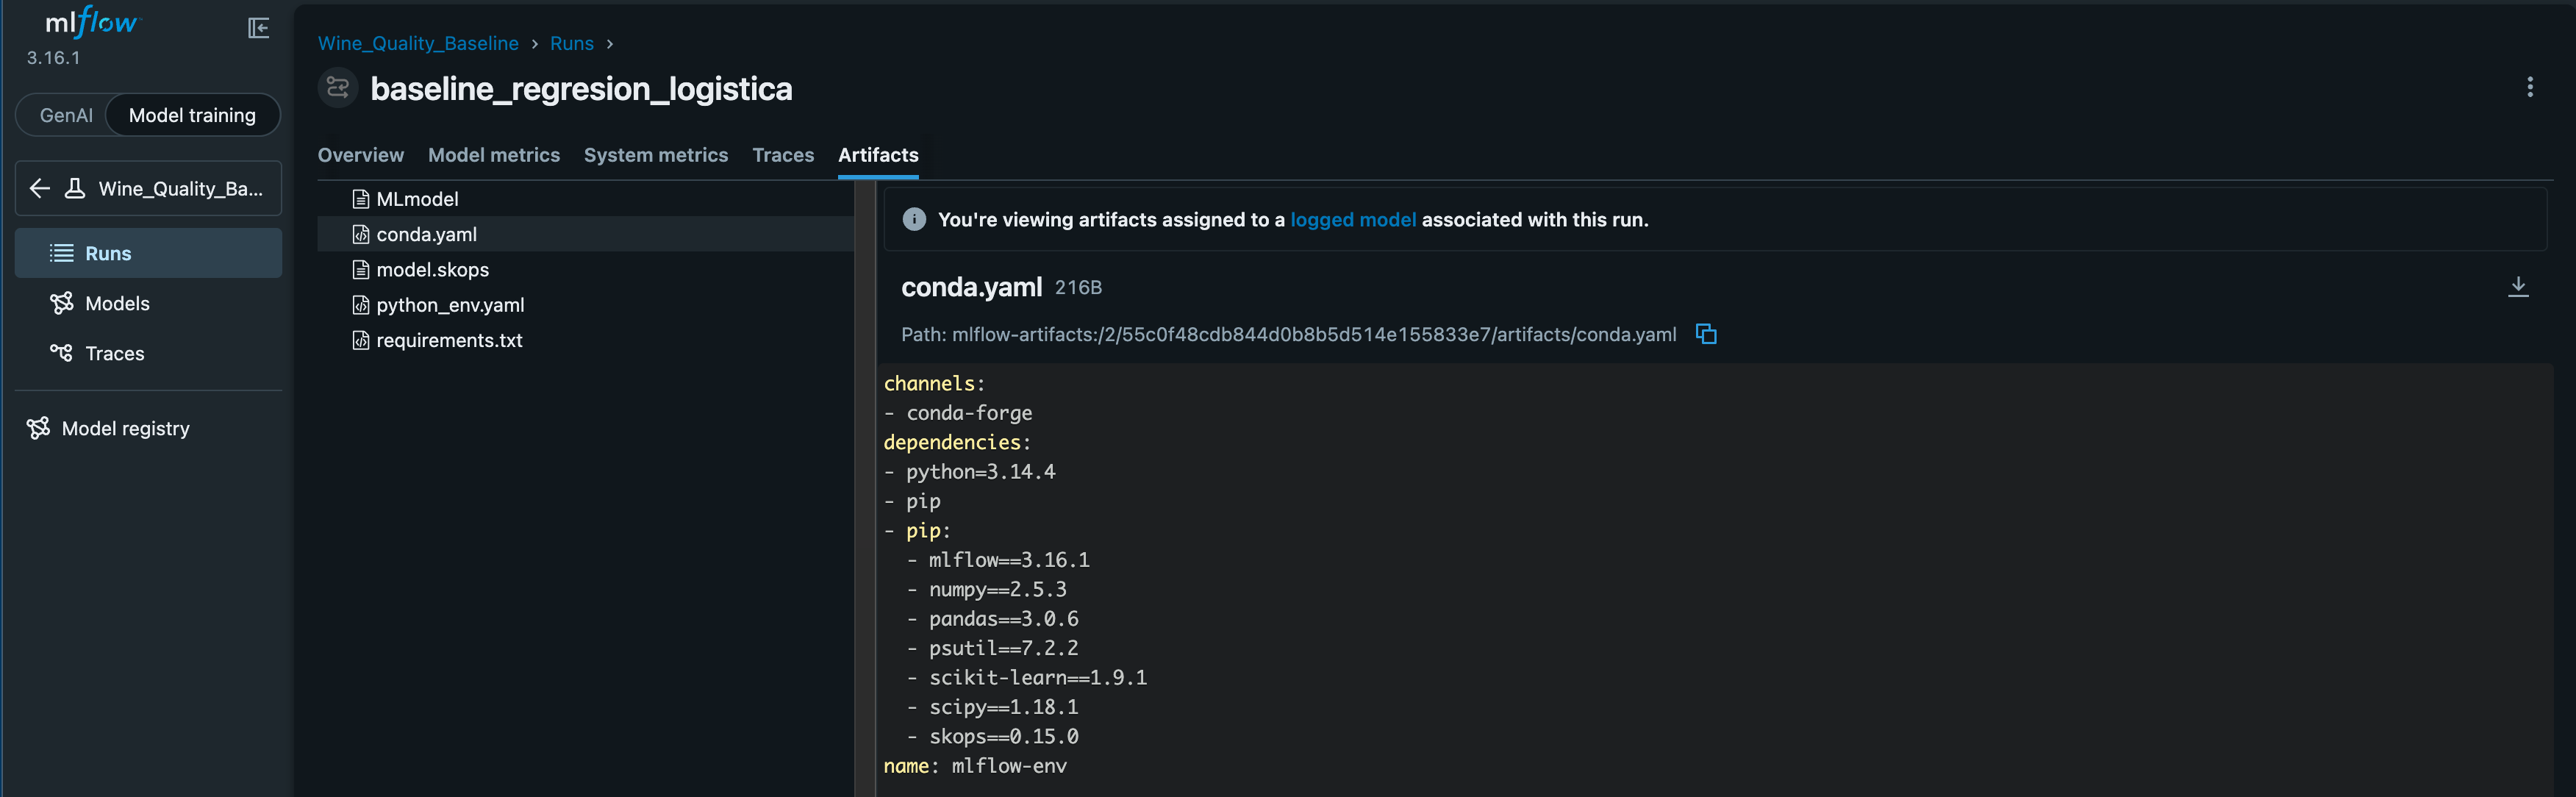

In [7]:
# =============================================================================
# EVIDENCIA VISUAL: CARGA DE CAPTURAS DE PANTALLA DE MLFLOW
# =============================================================================

from IPython.display import Image, display

# 1. Mostramos la captura general del experimento y sus corridas
print("Evidencia 1: Panel general de corridas en MLflow UI")
display(Image(filename="01.png", width=900))

# 2. Mostramos la captura del detalle de la corrida
print("\nEvidencia 2: Registro de parámetros, métricas")
display(Image(filename="02.png", width=900))

# 3. Mostramos la captura del detalle de los artefactos
print("\nEvidencia 3: Artefactos guardados")
display(Image(filename="03.png", width=900))

### **Paso 7: Reflexión sobre MLOps y Reducción de Deuda Técnica**

Al revisar el flujo de trabajo que desarrollé en este ejercicio, detecto varias mejoras puntuales que se deben aplicar usando buenas prácticas de MLOps. En primer lugar, la advertencia de falta de convergencia que arrojó el modelo dejó claro que las variables tienen escalas muy diferentes. Para solucionar esto de forma correcta y sin provocar fuga de información (*data leakage*), es indispensable empaquetar el escalado de datos (StandardScaler) y el modelo dentro de un Pipeline de Scikit-Learn. De esta manera, cualquier transformación se aplica de forma idéntica y automática tanto en el entrenamiento como al recibir datos nuevos para predecir.

En segundo lugar, aunque utilicé MLflow Tracking para registrar parámetros, métricas y el artefacto del modelo, el flujo todavía depende de correr celdas manualmente dentro de un Jupyter Notebook. En un proyecto real de producción, este código debe modularizarse en scripts de Python e integrarse en canalizaciones automáticas de integración continua (CI/CD) utilizando contenedores como Docker. Esto asegura que los experimentos se puedan reproducir en cualquier servidor sin depender de la computadora local de quien programa. Además, convendría añadir herramientas de validación de datos para verificar que las columnas y sus rangos numéricos cumplan con reglas estrictas antes de entrenar, evitando que datos corruptos alteren las predicciones.

En mi experiencia profesional dentro de la ingeniería de software y la seguridad informática, estos conceptos tienen una aplicación directa. Con frecuencia he visto problemas graves cuando la empresa adquiere nuevas herramientas y se intenta meter a la fuerza ese software ajeno al sistema principal mediante parches y código provisional. Con el paso del tiempo, estos arreglos rápidos se vuelven incompatibles, la documentación queda desfasada y se conservan rutas de código o configuraciones viejas que ya nadie entiende ni mantiene. Adoptar la disciplina de MLOps en sistemas de detección de amenazas y análisis de seguridad ayuda a evitar esta deuda técnica oculta. Registrar cada versión, validar los datos de entrada y automatizar las pruebas garantiza que las soluciones sean auditables, estables y seguras a largo plazo.

## Referencias Bibliográficas

* Géron, A. (2019). *Hands-on Machine Learning with Scikit-Learn, Keras and TensorFlow* (2.ª ed.). O’Reilly Media.
* Google. (2026). Gemini (basado en Gemini 3.8) [Modelo de lenguaje grande], utilizado para la revisión de redacción y código.
* Lauchande, N. (2021). *Machine Learning Engineering with MLFlow*. Packt Publishing.
* MLflow. (2024). *MLflow Tracking*. MLflow Documentation. https://mlflow.org/docs/latest/ml/tracking/
* Sculley, D., Holt, G., Golovin, D., Davydov, E., Phillips, T., Ebner, D., Chaudhary, V., Young, M., Crespo, J., & Dennison, D. (2015). Hidden technical debt in machine learning systems. En C. Cortes, N. Lawrence, D. Lee, M. Sugiyama, & R. Garnett (Eds.), *Advances in Neural Information Processing Systems* (Vol. 28, pp. 2503–2511). Curran Associates, Inc.
* Treveil, M., Omont, N., Stenac, C., Lefevre, K., Phan, D., Zentici, J., Lavoillotte, A., Miyazaki, M., & Heidmann, L. (2020). *Introducing MLOps: How to scale machine learning in the enterprise*. O’Reilly Media.